In [1]:
using ProjectRoot
using Pkg

Pkg.activate(@projectroot)
using Revise
using QuantumToolbox
using Peaks
using Revise
using ProgressMeter
using CairoMakie
using XoniumUnitCell
using LaTeXStrings

ProgressMeter.ijulia_behavior(:append)

CairoMakie.activate!(type="png")

  Activating 

project at `~/Projects/xonium/XoniumUnitCell.jl`


In [2]:
"""
    ncell(params::NamedTuple; subsys_nstate=10, diagonalize_subsys=true, set_energy_zero=true, etol=1e-9) -> CompositeQuantumSystem
Construct a composite quantum system representing a unit cell of `fluxonium` qubits, given a `NamedTuple` of parameters for each subsystem.
The function allows for optional diagonalization and truncation of each subsystem.
# Arguments
- `params::NamedTuple`: A `NamedTuple` where each key is a symbol representing a subsystem name, and each value is a `NamedTuple` of
   parameters for the `fluxonium` constructor.
- `subsys_nstate::Int`: The number of states to retain in each subsystem after truncation (default: 10).
- `diagonalize_subsys::Bool`: Whether to diagonalize each subsystem before truncation (default: true).
- `set_energy_zero::Bool`: Whether to set the ground state energy to zero when diagonalizing (default: true).
- `etol::Float64`: The energy tolerance for truncation when diagonalizing (default: 1e-9).
# Returns
- `CompositeQuantumSystem`: A composite quantum system representing the unit cell, with each subsystem constructed according to the 
   provided parameters and optionally diagonalized and truncated.
"""
function ncell(
    params::NamedTuple;
    subsys_nstate=10,
    diagonalize_subsys=true,
    set_energy_zero=true,
    etol=1e-9,
    kwargs...)::CompositeQuantumSystem
    return mapreduce(⊗, keys(params), values(params)) do n, p 
        if :EL ∈ keys(p) && p.EL != zero(p.EL)
            sys = fluxonium(;p..., name=n, kwargs...)
        else 
            sys = split_transmon(;p..., name=n,)
        end
        return (diagonalize_subsys ? to_energy_basis(sys; set_energy_zero, etol) : sys) |>
                sys -> truncate_sys(sys, subsys_nstate)
    end
end

function ζzz_vs_coupling(
        sys::CompositeQuantumSystem,
        s1_lbl::Symbol,
        s2_lbl::Symbol,
        gL_v::AbstractVector{<:Real},
        gC_v::AbstractVector{<:Real};
        showprogress::Bool=true,
    )
    ζzz = Matrix{Float64}(undef, length(gL_v), length(gC_v))
    gs = Array{Float64, 3}(undef, length(gL_v), length(gC_v), 2)
    H0 = sys.H
    nn, φφ = (sys[s1_lbl,op_lbl, s2_lbl, op_lbl] for op_lbl in (:n, :φ))
    loop_desc = "Calculating parasitic ZZ over coupling sweep"
    p = Progress(length(ζzz); showspeed=true, desc=loop_desc, 
        enabled=showprogress, barglyphs=BarGlyphs("[=> ]"), output=stdout)
    for idx in CartesianIndices(ζzz)
        i,j = idx.I
        gL, gC = gL_v[i], gC_v[j]
        ζzz[idx] = calc_ζzz(H0, nn, φφ, gL, gC)
        gs[idx, :] = [gL, gC]
        next!(p)
    end
    finish!(p)
    return ζzz, gs
end

function calc_ζzz(
        H0::AbstractQuantumObject,
        nn::AbstractQuantumObject,
        φφ::AbstractQuantumObject,
        gL::Real,
        gC::Real;
        gg::Int=1,
        eg::Int=2,
        ge::Int=3,
        ee::Int=4,
)
    H_tot = H0 + gL*φφ - gC*nn
    ens = eigenenergies(H_tot) .|> real
    ζzz = (ens[ee] + ens[gg]) - (ens[ge] + ens[eg])
    return ζzz
end

function calc_ζzz(
    H::AbstractQuantumObject;
    gg::Int=1,
    eg::Int=2,
    ge::Int=3,
    ee::Int=4,
    )
    ens = eigenenergies(H)
    return (ens[ee] + ens[gg]) - (ens[ge] + ens[eg])
end

function track_spectrum(sys, λop, λvals; showprogress::Bool=true,
    set_energy_zero::Bool=true)
    H0 = sys.H
    dim = size(H0)[1]
    ens = Matrix{Float64}(undef, length(λvals), dim)
    loop_desc = "Calculating spectrum over H perturbation"
    p = Progress(length(λvals); showspeed=true, desc=loop_desc, enabled=showprogress)
    for (i, λ) in pairs(λvals)
        H = H0 + λ*λop
        evals = eigenenergies(H)
        e0 = set_energy_zero ? evals[1] : 0.0
        ens[i,:] = evals .- e0 .|> real
        next!(p)
    end
    finish!(p)
    return ens
end

function to_ħGHz(params::Union{NamedTuple, Dict{:Symbol, <:Real}})::NamedTuple 
    return map(keys(params), values(params)) do k, v 
        if k ∈ (:EC, :EL, :EJ)
            return k => 2π * v 
        else 
            return k=>v
        end
    end
end


function μ_φ(
    sys::AbstractQuantumSystem;
    φA::Union{AbstractQuantumObject, Nothing} = nothing,
    gg::Union{Int, Symbol} = :gg,
    eg::Union{Int, Symbol} = :eg,
    ge::Union{Int, Symbol} = :ge,
    sA_lbl::Symbol=:fA,
    sB_lbl::Symbol=:fB,
    )
    φA = isnothing(φA) ? sys[sA_lbl, :φ] : φA
    ψ00, ψ01, ψ10 = [state(sys, lbl)[2] for lbl in (gg, ge, eg)]
    return (ψ00' * φA * ψ01) / (ψ00' * φA * ψ10) |> abs
end

function μ_φ(;
    φA::AbstractQuantumObject,
    gg::AbstractQuantumObject,
    eg::AbstractQuantumObject,
    ge::AbstractQuantumObject,
)
    return (gg' * φA * ge) / (gg' * φA * eg) |> abs
end

function long_coupling_sweep(
    sys::AbstractQuantumSystem,
    JL_v::AbstractVector{Float64},
    JC_v::AbstractVector{Float64};
    sA_lbl::Symbol=:fA,
    sB_lbl::Symbol=:fB,
    showprogress::Bool=true,
    )
    # extract two-qubit operators and bare hamiltonian
    φA = sys[sA_lbl, :φ]
    φφ = sys[sA_lbl, :φ, sB_lbl, :φ]
    nn = sys[sA_lbl, :n, sB_lbl, :n]
    H0 = sys.H

    # get number of swept parameters
    nL, nC = [length(v) for v in (JL_v, JC_v)]

    # pre-allocate output arrays
    J_mtrx = Array{Float64, 3}(undef, nL, nC, 2)
    μφ_mtrx = Matrix{Float64}(undef, nL, nC)
    ζzz_mtrx = Matrix{Float64}(undef, nL, nC)

    # assuming no energy crossings, state ordering should remain constant
    # compute dressed state indices here to avoid repeated computation
    s_lbls = (:gg, :eg, :ge, :ee)
    s_idx = (;(lbl=>state_idx(sys, lbl) for lbl in s_lbls)...)

    # sweep over input arrays, collect statistics
    desc = "Fluxonium Blueprint Parameter Sweep for Fig 5 a-c"
    p = Progress(nL*nC; showspeed=true, desc=desc, enabled=showprogress)
    for (i, Jl) in pairs(JL_v), (j, Jc) in pairs(JC_v)
        H = H0 + Jl*φφ - Jc*nn # add coupling term
        # get eigenstates labeled in bare basis
        λs, ψs = eigenstates(H)
        sts = (;(k=>ψs[v] for (k,v) in pairs(s_idx))...)
        # calc ζzz and entangeling metric
        ζzz_mtrx[i,j] = (λs[4] + λs[1]) - (λs[2] + λs[3]) |> real 
        μφ_mtrx[i,j] = μ_φ(;φA=φA, gg=sts.gg, eg=sts.eg, ge=sts.ge)
        J_mtrx[i,j,:] .= (Jl, Jc)
        next!(p)
    end
    finish!(p)
    return ζzz_mtrx, μφ_mtrx, J_mtrx
end


long_coupling_sweep (generic function with 1 method)

## Long Fluxonium Blueprint Cell

Define fluxonia and uncoupled cell

In [3]:
fbA_params = (EJ=4.0, EC=1.0, EL=0.9, δϕ=π, n_g=0.0, Φext_incos=true) |> tounit_ħ
fbB_params = (EJ=4.0, EC=1.0, EL=1.0, δϕ=π, n_g=0.0, Φext_incos=true) |> tounit_ħ
fbA, fbB = [
    fluxonium(;p..., name=lbl, nlev=40) |> sys -> to_energy_basis(sys; etol=1e-9) |> sys -> truncate_sys(sys, 5)
    for (p, lbl) in zip([fbA_params, fbB_params], (:fA, :fB))
]
fb_cell = fbA ⊗ fbB;


Define parameter ranges for inductive and capacitive couplings 

In [4]:
MHzh_conv = 2π * 1e-3 # prefactor for converting MHz(h=1) values to GHz(ħ=1)

Jl_v = range(0.0, 2.0, 300) .* MHzh_conv |> collect
Jc_v = range(0.0, 80, 300) .* MHzh_conv |> collect

300-element Vector{Float64}:
 0.0
 0.0016811198146299898
 0.0033622396292599796
 0.005043359443889969
 0.006724479258519959
 0.00840559907314995
 0.010086718887779938
 0.011767838702409928
 0.013448958517039918
 0.015130078331669908
 0.0168111981462999
 0.01849231796092989
 0.020173437775559876
 ⋮
 0.48416250661343707
 0.48584362642806705
 0.48752474624269704
 0.489205866057327
 0.490886985871957
 0.492568105686587
 0.49424922550121697
 0.495930345315847
 0.497611465130477
 0.499292584945107
 0.5009737047597369
 0.5026548245743669

Run Sweep

In [5]:
ζzz_fb, μφ, Js = long_coupling_sweep(fb_cell, Jl_v, Jc_v);

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c   0%  ETA: 5:24:35 ( 0.22  s/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c   7%  ETA: 0:00:32 ( 0.38 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c   7%  ETA: 0:00:31 ( 0.37 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c   8%  ETA: 0:00:30 ( 0.37 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c   8%  ETA: 0:00:30 ( 0.36 ms/it)

...

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c  99%  ETA: 0:00:00 ( 0.29 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c  99%  ETA: 0:00:00 ( 0.29 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c  99%  ETA: 0:00:00 ( 0.29 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c  99%  ETA: 0:00:00 ( 0.29 ms/it)

Fluxonium Blueprint Parameter Sweep for Fig 5 a-c 100% Time: 0:00:26 ( 0.29 ms/it)


Re-create plots 5(a-c)

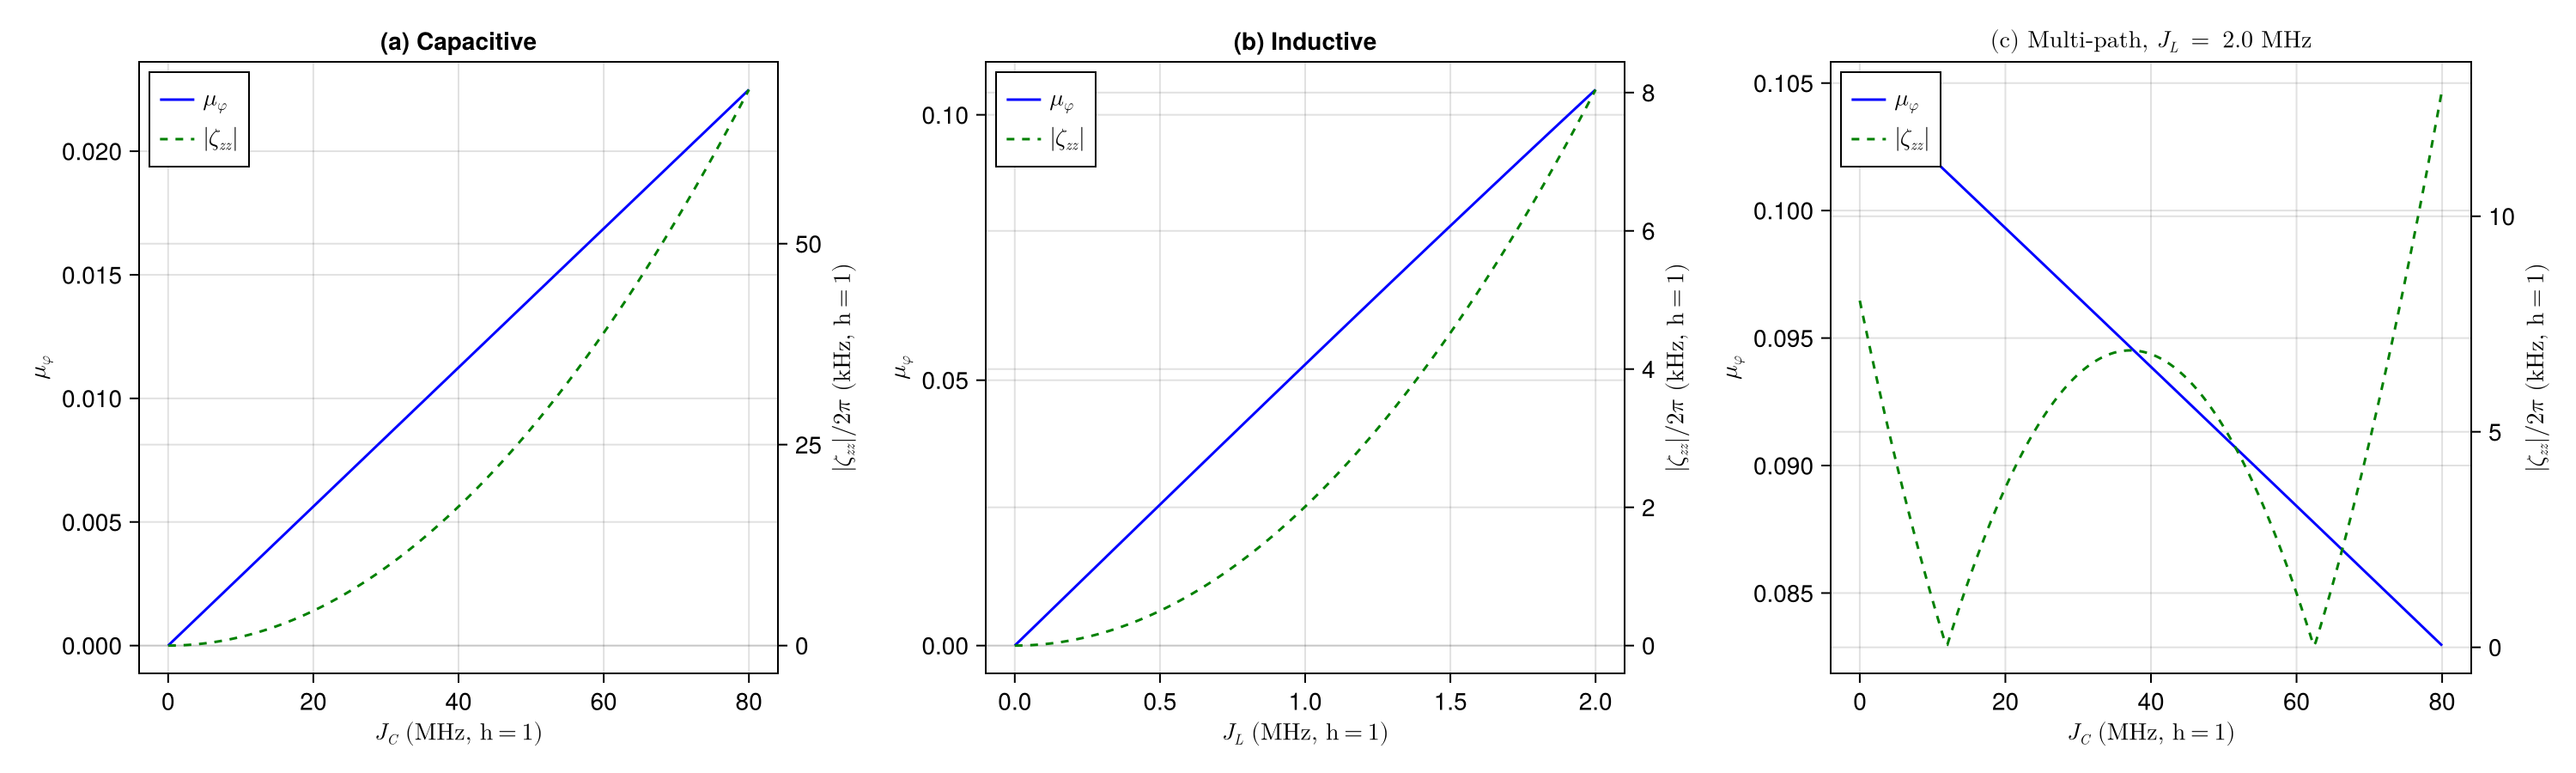

In [6]:
"""
    plot_ζzz_μφ(subfig, J, ζzz, μφ; x_lbl, yL_lbl, yR_lbl) -> (ax_μφ, ax_ζzz)

Dual-axis plot of the normalized cross matrix element `μφ` (left, blue) and `|ζzz|/2π` (right, green dashed)
against a coupling strength. `J` is in MHz (h=1) and `ζzz` in rad/ns (ħ=1); it is converted to kHz here.
"""
function plot_ζzz_μφ(
    subfig::CairoMakie.GridPosition,
    J::AbstractVector{<:Real},
    ζzz::AbstractVector{<:Real},
    μφ::AbstractVector{<:Real};
    yL_lbl::AbstractString=L"\mu_\varphi",
    yR_lbl::AbstractString=L"$|\zeta_{zz}|/2\pi$ (kHz, h=1)",
    x_lbl::AbstractString="J",
    title::AbstractString="",
    )
    ax_μφ = Axis(subfig; xlabel=x_lbl, ylabel=yL_lbl, title=title)
    ax_ζzz = Axis(subfig; ylabel=yR_lbl, yaxisposition=:right)
    hidexdecorations!(ax_ζzz)
    hidespines!(ax_ζzz, :l, :b, :t)
    l_μ = lines!(ax_μφ, J, μφ; color=:blue)
    l_ζ = lines!(ax_ζzz, J, abs.(ζzz) .* (1e6 / 2π); color=:green, linestyle=:dash)
    linkxaxes!(ax_μφ, ax_ζzz)
    axislegend(ax_μφ, [l_μ, l_ζ], [L"\mu_\varphi", L"|\zeta_{zz}|"]; position=:lt)
    return ax_μφ, ax_ζzz
end

Jl_MHz, Jc_MHz = Jl_v ./ MHzh_conv, Jc_v ./ MHzh_conv
fig = Figure(size=(1500, 450))

# (a) capacitive coupling only, (b) inductive coupling only, (c) multi-path with J_L = 2 MHz
plot_ζzz_μφ(fig[1,1], Jc_MHz, ζzz_fb[1,:], μφ[1,:]; x_lbl=L"$J_C$ (MHz, h=1)", title="(a) Capacitive")
plot_ζzz_μφ(fig[1,2], Jl_MHz, ζzz_fb[:,1], μφ[:,1]; x_lbl=L"$J_L$ (MHz, h=1)", title="(b) Inductive")
plot_ζzz_μφ(fig[1,3], Jc_MHz, ζzz_fb[end,:], μφ[end,:]; x_lbl=L"$J_C$ (MHz, h=1)",
    title=L"(c) Multi-path, $J_L$ = %$(Jl_MHz[end]) MHz")
fig

## First Sweep, Check $\zeta_{zz}$ cancellation in nearly degenerate 2-cell

Using the two-cell defined in the previous code block, we would like to sweep over possible inductive and capacitive couplings to see if we can find a region with negligible ZZ coupling.



In [7]:
flA_params = (;EJ = 7.0, EC=1, EL=1, δϕ=π, n_g=0.0, Φext_incos=true) |> tounit_ħ
flB_params = (;EJ = 6.8, EC=1, EL=1, δϕ=π, n_g=0.0, Φext_incos=true) |> tounit_ħ

f1 = fluxonium(;flA_params..., name=:f1, nlev=30) |> sys -> to_energy_basis(sys; etol=1e-9) |> sys -> truncate_sys(sys, 5)
f2 = fluxonium(;flB_params..., name=:f2, nlev=30) |> sys -> to_energy_basis(sys; etol=1e-9) |> sys -> truncate_sys(sys, 5)

two_cell = f1 ⊗ f2;

In [8]:
# inductive and capacitive coupling strengths in units of GHz [ħ=1]
# g_ind_rng = range(1.0, 300.0, length=100) * 2π * 1e-3 |> collect
# g_cap_rng = range(1.0, 4.0, length=100) * 2π  |> collect
GHzħ_conv = 2π * 1e-3
g_Lv = range(0, 100, length=300) .* GHzħ_conv |> collect
g_Cv = range(0, 50, length=300) .* GHzħ_conv  |> collect

ζzz, gs = ζzz_vs_coupling(two_cell, :f1, :f2, g_Lv, g_Cv);



Calculating parasitic ZZ over coupling sweep   0%  ETA: 7:51:02 ( 0.31  s/it)

Calculating parasitic ZZ over coupling sweep   1%  ETA: 0:01:52 ( 1.25 ms/it)

Calculating parasitic ZZ over coupling sweep   1%  ETA: 0:01:09 ( 0.77 ms/it)

Calculating parasitic ZZ over coupling sweep   2%  ETA: 0:00:50 ( 0.57 ms/it)

Calculating parasitic ZZ over coupling sweep   3%  ETA: 0:00:41 ( 0.47 ms/it)

...

Calculating parasitic ZZ over coupling sweep  97%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep  98%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep  99%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep  99%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep 100% Time: 0:00:16 ( 0.18 ms/it)


┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie ~/.julia/packages/Makie/Iy6pu/src/scenes.jl:264


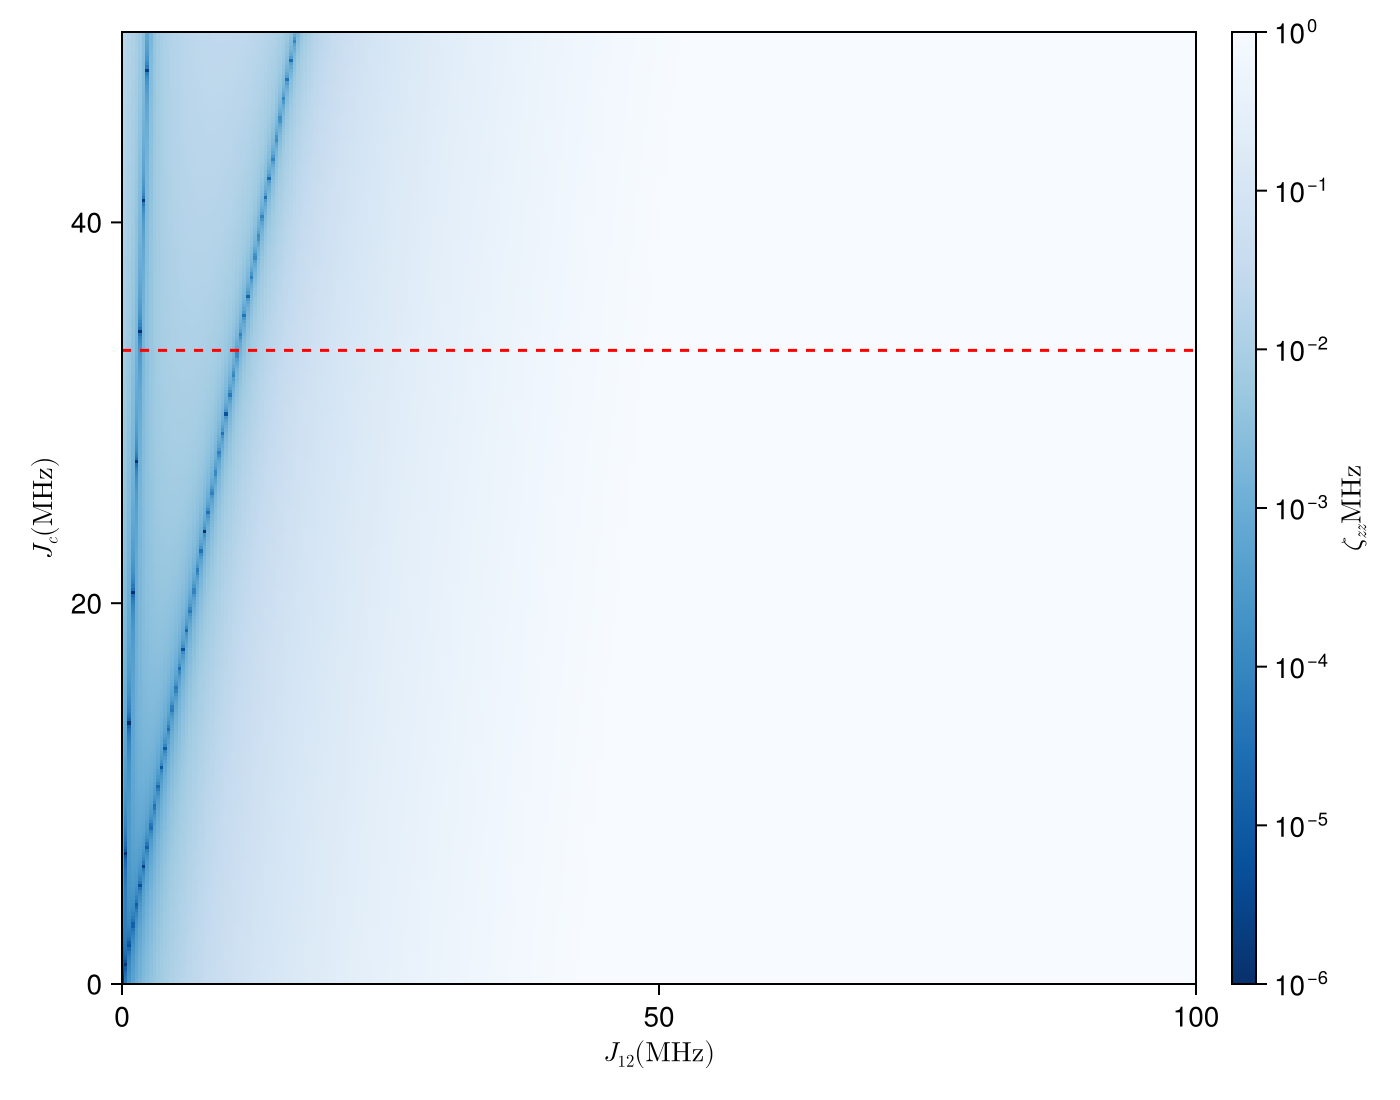

In [9]:
Z = clamp.(abs.(ζzz) * 1e3, 1e-6, 1) 
fig, ax = zz_heatmap_figure(Z, x=g_Lv ./ GHzħ_conv, y=g_Cv .*(1e3/2π), clims=(minimum(Z), maximum(Z)), 
    xlabel=L"J_{12} (\mathrm{MHz})",
    ylabel=L"J_c (\mathrm{MHz})", colorbar_label=L"\zeta_{zz}\mathrm{MHz}")
fig

gC_idx = 200
hlines!(ax, g_Cv[gC_idx]/ GHzħ_conv, color=:red, linestyle=:dash)
fig

In [10]:
nn = two_cell[:f1, :n, :f2, :n]
φφ = two_cell[:f1, :φ, :f2, :φ]
ens = track_spectrum(two_cell + g_Cv[gC_idx]*nn, φφ, g_Lv);

Calculating spectrum over H perturbation   3%  ETA: 0:00:04 (12.51 ms/it)

Calculating spectrum over H perturbation 100% Time: 0:00:00 ( 0.85 ms/it)


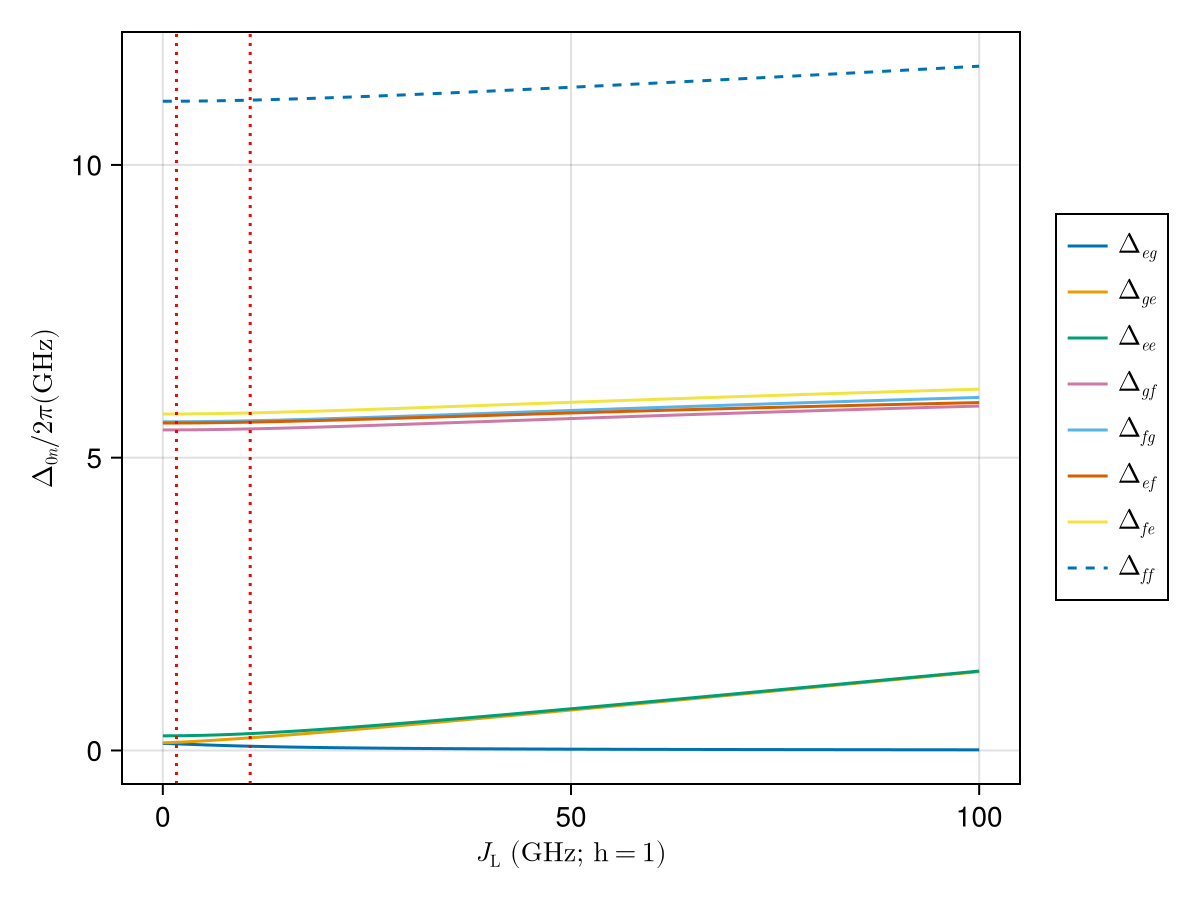

In [11]:
fig_ens = Figure()
xlabel = L"$J_{\mathrm{L}}$ (GHz; h=1)"
ylabel = L"Δ_{0n}/2π(\mathrm{GHz})"
title = "Spectrum vs Inductive Coupling"
ax_ens = Axis(
    fig_ens[1,1];
    xlabel=xlabel,
    ylabel=ylabel,
)
fig = Figure()
ax = Axis(fig[1,1], yscale=log10)
lines!(ax, g_Lv[2:end] .* (1e3/2π), Z[2:end,gC_idx])
fig
state_lbls = (:gg, :eg, :ge, :ee,
              :gf, :fg, :ff, :ef, :fe,
              :gh, :hg, :hh, :eh, :he, :fh, :hf,)
state_lbls = (;(lbl=>state_idx(two_cell, lbl) for lbl in state_lbls)...)


max_lev = 3
e_levels = [:eg, :ge, :ee, :gf, :fg, :ef, :fe, :ff]
gL_min, gL_max = (argmin(g_Lv ./ GHzħ_conv .- v .|> abs) for v in (138, 142))
for n in e_levels
    #en_n = ens[gL_min: gL_max,n+1] ./ 2π 
    en_n = ens[:, state_lbls[n]] ./2π
    lines!(ax_ens, g_Lv[:] .* (1e3/2π), en_n, label=L"Δ_{%$(String(n))}",
    cycle=[:color, :linestyle], colormap=:darktest)
end
#print(ens[:, 3] .- ens[:, 4])
# add vertical lines at location of minima
min_idx, _ = findminima(Z[:,gC_idx])
isempty(min_idx) || vlines!(ax_ens, g_Lv[min_idx] .* (1e3/2π); color=:red, linestyle=:dot)
Legend(fig_ens[1,2], ax_ens)
fig_ens

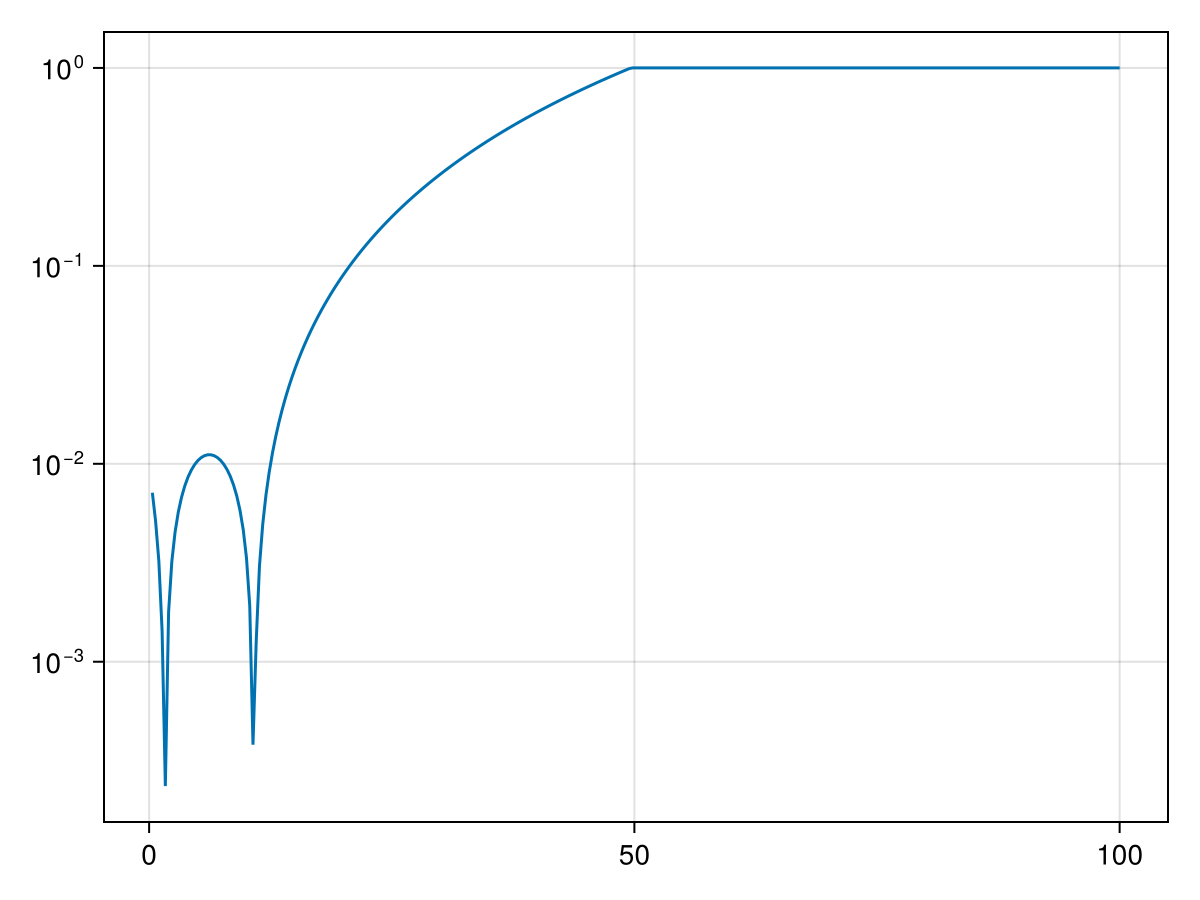

In [12]:
fig = Figure()
ax = Axis(fig[1,1], yscale=log10)
lines!(ax, g_Lv[2:end] .* (1e3/2π), Z[2:end,gC_idx])
fig

## Second Sweep, Check $\zeta_{zz}$ cancellation in 2-cell with Heavy and Light Fluxonia

In [13]:
flA_params = (;EJ = 12.0, EC=0.4, EL=1, δϕ=π, n_g=0.0, Φext_incos=true) |> tounit_ħ
flB_params = (;EJ = 3, EC=2, EL=1, δϕ=π, n_g=0.0, Φext_incos=true) |> tounit_ħ

f1 = fluxonium(;flA_params..., name=:f1, nlev=30) |> sys -> to_energy_basis(sys; etol=1e-9) |> sys -> truncate_sys(sys, 5)
f2 = fluxonium(;flB_params..., name=:f2, nlev=30) |> sys -> to_energy_basis(sys; etol=1e-9) |> sys -> truncate_sys(sys, 5)

two_cell = f1 ⊗ f2;

GHzħ_conv = 2π * 1e-3
g_Lv = range(0, 250, length=300) .* GHzħ_conv |> collect
g_Cv = range(0, 2000, length=300) .* GHzħ_conv  |> collect

ζzz, gs = ζzz_vs_coupling(two_cell, :f1, :f2, g_Lv, g_Cv);



Calculating parasitic ZZ over coupling sweep   1%  ETA: 0:00:12 ( 0.14 ms/it)

Calculating parasitic ZZ over coupling sweep   2%  ETA: 0:00:10 ( 0.12 ms/it)

Calculating parasitic ZZ over coupling sweep   3%  ETA: 0:00:11 ( 0.13 ms/it)

Calculating parasitic ZZ over coupling sweep   4%  ETA: 0:00:12 ( 0.14 ms/it)

Calculating parasitic ZZ over coupling sweep   5%  ETA: 0:00:13 ( 0.15 ms/it)

...

Calculating parasitic ZZ over coupling sweep  98%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep  98%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep  99%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep  99%  ETA: 0:00:00 ( 0.18 ms/it)

Calculating parasitic ZZ over coupling sweep 100% Time: 0:00:16 ( 0.18 ms/it)


┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie ~/.julia/packages/Makie/Iy6pu/src/scenes.jl:264


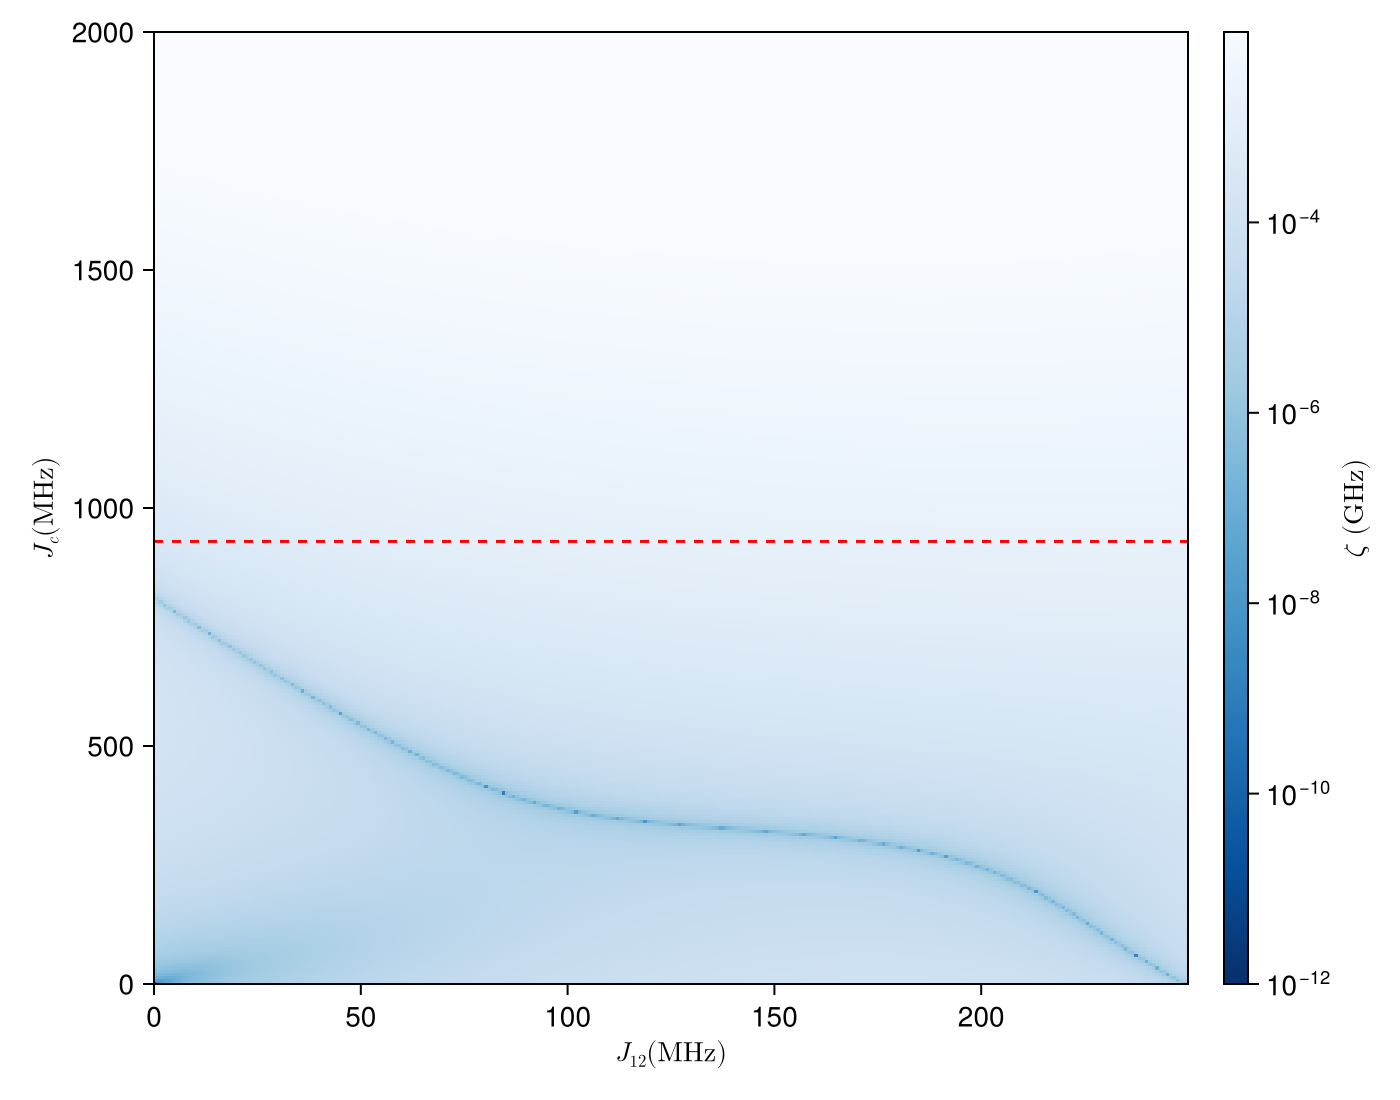

In [14]:

Z = clamp.(abs.(ζzz), 1e-12, 1e-2)
fig, ax = zz_heatmap_figure(Z, x=g_Lv ./ GHzħ_conv, y=g_Cv .*(1e3/2π), clims=(minimum(Z), maximum(Z)), 
    xlabel=L"J_{12} (\mathrm{MHz})",
    ylabel=L"J_c (\mathrm{MHz})",)
fig

gC_idx = 140
hlines!(ax, g_Cv[gC_idx]/ GHzħ_conv, color=:red, linestyle=:dash)
fig

In [15]:

nn = two_cell[:f1, :n, :f2, :n]
φφ = two_cell[:f1, :φ, :f2, :φ]
ens = track_spectrum(two_cell + g_Cv[gC_idx]*nn, φφ, g_Lv);

[-0.0005683829232410176, -0.0005553435583891542, -0.0005422771616938604, -0.0005291840449554996, -0.0005160645207809011, -0.0005029189017413671, -0.0004897475007972218, -0.00047655063102602924, -0.0004633286055160113, -0.00045008173752769665, -0.0004368103397869305, -0.00042351472548318725, -0.00041019520730145587, -0.00039685209731921134, -0.00038348570770807555, -0.0003700963497248466, -0.00035668433422308965, -0.0003432499716602422, -0.0003297935716268796, -0.0003163154425713799, -0.00030281589256375696, -0.00028929522875742464, -0.00027575375693089654, -0.00026219178204200944, -0.0002486096077145561, -0.0002350075363040105, -0.00022138586921904846, -0.00020774490614705599, -0.0001940849455284166, -0.00018040628399518255, -0.0001667092169110873, -0.00015299403791502186, -0.00013926103884109864, -0.00012551050966713717, -0.00011174273855729666, -9.795801206458066e-5, -8.415661424443499e-5, -7.033882754114984e-5, -5.650493197251194e-5, -4.265520545132517e-5, -2.8789924067851302e-5, -1

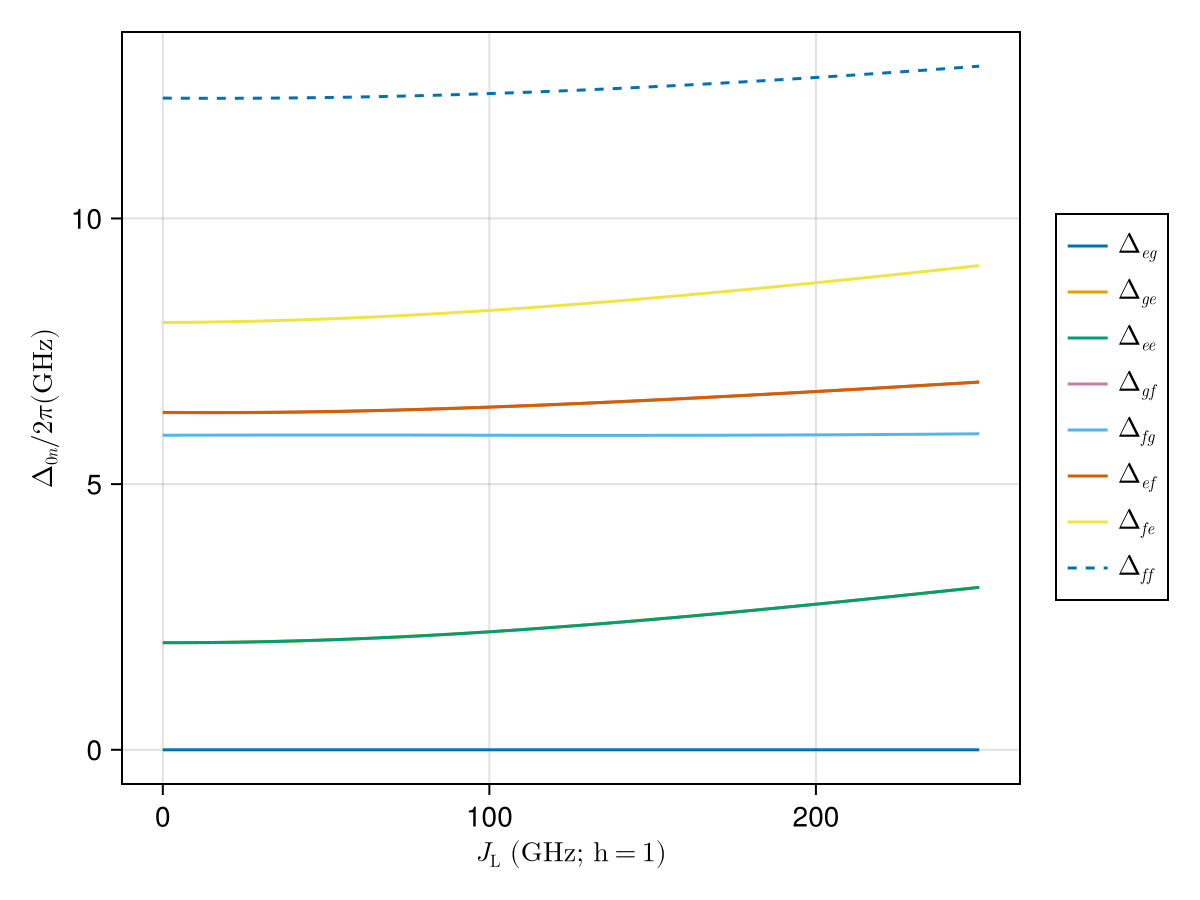

In [16]:
nn
nn
fig_ens = Figure()
xlabel = L"$J_{\mathrm{L}}$ (GHz; h=1)"
ylabel = L"Δ_{0n}/2π(\mathrm{GHz})"
title = "Spectrum vs Inductive Coupling"
ax_ens = Axis(
    fig_ens[1,1];
    xlabel=xlabel,
    ylabel=ylabel,
)

state_lbls = (:gg, :eg, :ge, :ee,
              :gf, :fg, :ff, :ef, :fe,
              :gh, :hg, :hh, :eh, :he, :fh, :hf,)
state_lbls = (;(lbl=>state_idx(two_cell, lbl) for lbl in state_lbls)...)


max_lev = 3
e_levels = [:eg, :ge, :ee, :gf, :fg, :ef, :fe, :ff]
gL_min, gL_max = (argmin(g_Lv ./ GHzħ_conv .- v .|> abs) for v in (138, 142))
for n in e_levels
    #en_n = ens[gL_min: gL_max,n+1] ./ 2π 
    en_n = ens[:, state_lbls[n]] ./2π
    lines!(ax_ens, g_Lv[:] .* (1e3/2π), en_n, label=L"Δ_{%$(String(n))}",
    cycle=[:color, :linestyle], colormap=:darktest)
end
print(ens[:, 3] .- ens[:, 4])
# add vertical lines at location of minima
min_idx, _ = findminima(Z[:,gC_idx])
isempty(min_idx) || vlines!(ax_ens, g_Lv[min_idx] .* (1e3/2π); color=:red, linestyle=:dot)
Legend(fig_ens[1,2], ax_ens)
fig_ens

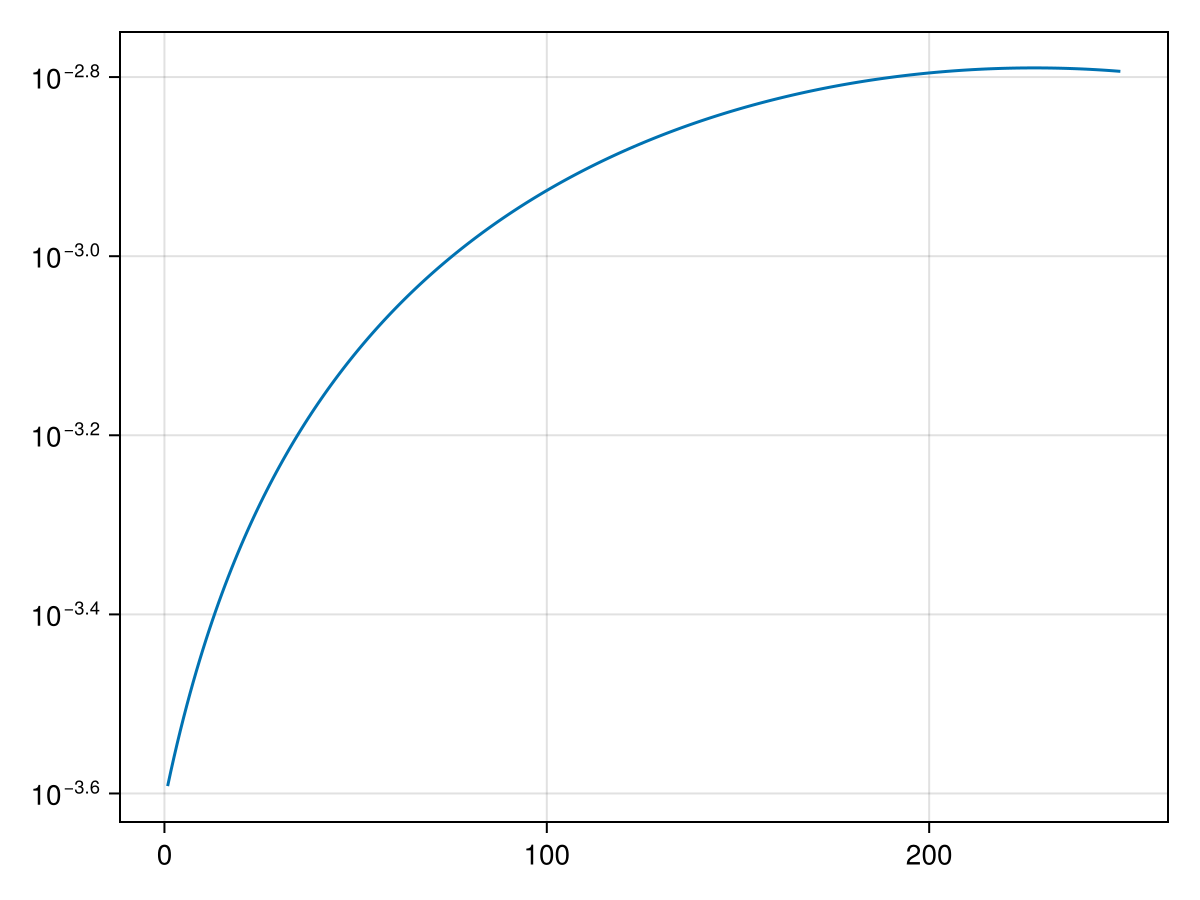

In [17]:
fig = Figure()
ax = Axis(fig[1,1], yscale=log10)
lines!(ax, g_Lv[2:end] .* (1e3/2π), Z[2:end,gC_idx])
fig